In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt

from torchvision.datasets import CIFAR10

from sklearn.model_selection import train_test_split
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [3]:
C_VALUES = [0.01, 0.1, 1.0]
PCA_OPTIONS = [None, 300, 400, 512]

MAX_ITER = 1000
SEED = 42

CLASS_NAMES = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

In [4]:
train_dataset = CIFAR10(
    root="data",
    train=True,
    download=True
)

test_dataset = CIFAR10(
    root="data",
    train=False,
    download=True
)

X_train_full = train_dataset.data
y_train_full = np.array(train_dataset.targets)

X_test = test_dataset.data
y_test = np.array(test_dataset.targets)


X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.1,
    stratify=y_train_full,
    random_state=SEED
)

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

# Перетворення зображень у вектори
X_train = X_train.reshape(len(X_train), -1)
X_val = X_val.reshape(len(X_val), -1)
X_test = X_test.reshape(len(X_test), -1)

# Нормалізація пікселів до діапазону [0, 1]
X_train = X_train.astype(np.float64) / 255.0
X_val = X_val.astype(np.float64) / 255.0
X_test = X_test.astype(np.float64) / 255.0

print("\nTrain:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)

print("Min pixel value:", X_train.min())
print("Max pixel value:", X_train.max())


Train: (45000, 32, 32, 3) (45000,)
Validation: (5000, 32, 32, 3) (5000,)
Test: (10000, 32, 32, 3) (10000,)

Train: (45000, 3072)
Validation: (5000, 3072)
Test: (10000, 3072)
Min pixel value: 0.0
Max pixel value: 1.0


In [5]:
results = []

best_model = None
best_val_accuracy = 0
best_config = None

for pca_components in PCA_OPTIONS:
    for c_value in C_VALUES:

        pipeline_steps = []

        if pca_components is not None:
            pipeline_steps.append((
                "pca",
                PCA(n_components=pca_components, random_state=SEED)
            ))

        pipeline_steps.append((
            "logistic_regression",
            LogisticRegression(
                C=c_value,
                max_iter=MAX_ITER,
                solver="lbfgs"
            )
        ))

        model = Pipeline(steps=pipeline_steps)

        start_time = time.perf_counter()
        model.fit(X_train, y_train)
        training_time = time.perf_counter() - start_time

        train_accuracy = accuracy_score(
            y_train, model.predict(X_train)
        )

        val_accuracy = accuracy_score(
            y_val, model.predict(X_val)
        )

        results.append({
            "PCA": pca_components,
            "C": c_value,
            "Train Accuracy": train_accuracy,
            "Validation Accuracy": val_accuracy,
            "Training Time": training_time
        })

        print(
            f"PCA={pca_components}, C={c_value} | "
            f"Train={train_accuracy:.4f}, "
            f"Val={val_accuracy:.4f}, "
            f"Time={training_time:.2f}s",
            flush=True
        )

        if val_accuracy > best_val_accuracy:
            best_val_accuracy = val_accuracy
            best_model = model
            best_config = (pca_components, c_value)

PCA=None, C=0.01 | Train=0.4507, Val=0.4204, Time=145.10s
PCA=None, C=0.1 | Train=0.4778, Val=0.4108, Time=253.93s


C:\Users\eugen\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


PCA=None, C=1.0 | Train=0.4896, Val=0.3932, Time=288.24s
PCA=300, C=0.01 | Train=0.4326, Val=0.4098, Time=22.71s
PCA=300, C=0.1 | Train=0.4369, Val=0.4138, Time=23.27s
PCA=300, C=1.0 | Train=0.4367, Val=0.4142, Time=23.44s
PCA=400, C=0.01 | Train=0.4396, Val=0.4146, Time=20.18s
PCA=400, C=0.1 | Train=0.4427, Val=0.4142, Time=22.42s
PCA=400, C=1.0 | Train=0.4419, Val=0.4130, Time=23.70s
PCA=512, C=0.01 | Train=0.4417, Val=0.4170, Time=23.40s
PCA=512, C=0.1 | Train=0.4481, Val=0.4138, Time=29.55s
PCA=512, C=1.0 | Train=0.4475, Val=0.4104, Time=30.59s


In [6]:
print("\n=== Best Configuration ===")
print(f"PCA: {best_config[0]}")
print(f"C: {best_config[1]}")
print(f"Best Validation Accuracy: {best_val_accuracy:.4f}")

best_result = next(
    result for result in results
    if result["PCA"] == best_config[0]
    and result["C"] == best_config[1]
)

print(f"Training Time: {best_result['Training Time']:.2f} seconds")


=== Best Configuration ===
PCA: None
C: 0.01
Best Validation Accuracy: 0.4204
Training Time: 145.10 seconds


In [7]:
# Передбачення на тестовій вибірці
y_pred = best_model.predict(X_test)

# Обчислення метрик
test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, average="macro", zero_division=0)
test_recall = recall_score(y_test, y_pred, average="macro", zero_division=0)
test_f1 = f1_score(y_test, y_pred, average="macro", zero_division=0)

print("\n=== Test Results ===")
print(f"Test Accuracy:  {test_accuracy:.4f}")
print(f"Test Precision: {test_precision:.4f}")
print(f"Test Recall:    {test_recall:.4f}")
print(f"Test F1-score:  {test_f1:.4f}")


=== Test Results ===
Test Accuracy:  0.4149
Test Precision: 0.4105
Test Recall:    0.4149
Test F1-score:  0.4114


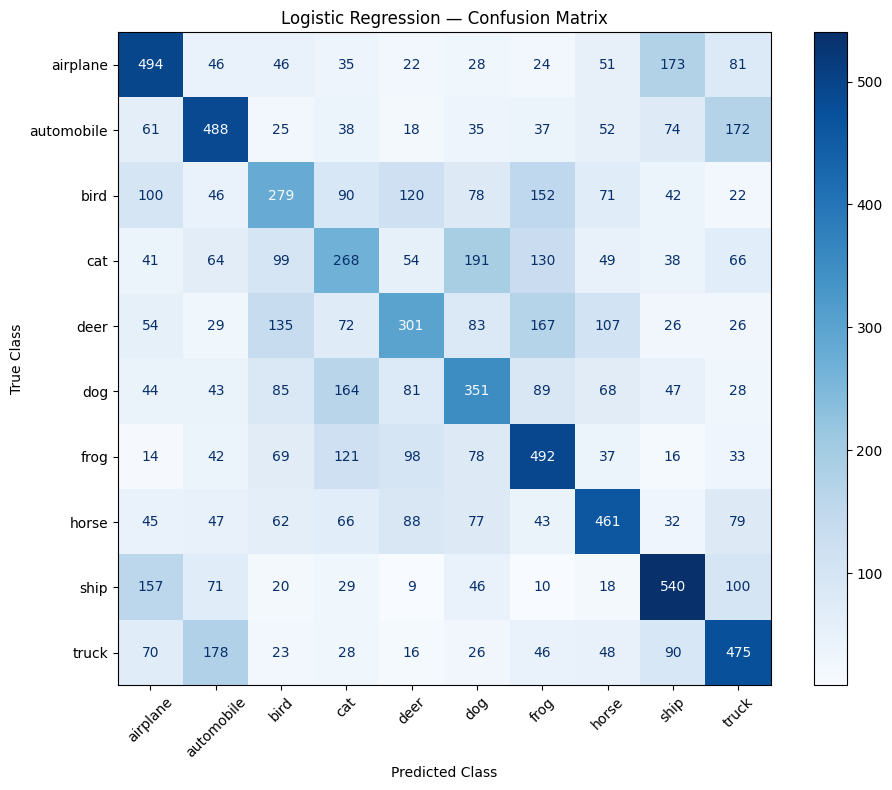

In [8]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASS_NAMES
)

fig, ax = plt.subplots(figsize=(10, 8))

disp.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    xticks_rotation=45
)

ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")
ax.set_title("Logistic Regression — Confusion Matrix")

plt.tight_layout()
plt.show()

In [9]:
print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4,
    zero_division=0
))

              precision    recall  f1-score   support

    airplane     0.4574    0.4940    0.4750      1000
  automobile     0.4630    0.4880    0.4752      1000
        bird     0.3310    0.2790    0.3028      1000
         cat     0.2942    0.2680    0.2805      1000
        deer     0.3730    0.3010    0.3331      1000
         dog     0.3535    0.3510    0.3522      1000
        frog     0.4134    0.4920    0.4493      1000
       horse     0.4792    0.4610    0.4699      1000
        ship     0.5009    0.5400    0.5197      1000
       truck     0.4390    0.4750    0.4563      1000

    accuracy                         0.4149     10000
   macro avg     0.4105    0.4149    0.4114     10000
weighted avg     0.4105    0.4149    0.4114     10000



In [10]:
heatmap_data = np.zeros((len(PCA_OPTIONS), len(C_VALUES)))

for result in results:
    row = PCA_OPTIONS.index(result["PCA"])
    col = C_VALUES.index(result["C"])

    heatmap_data[row, col] = result["Validation Accuracy"]

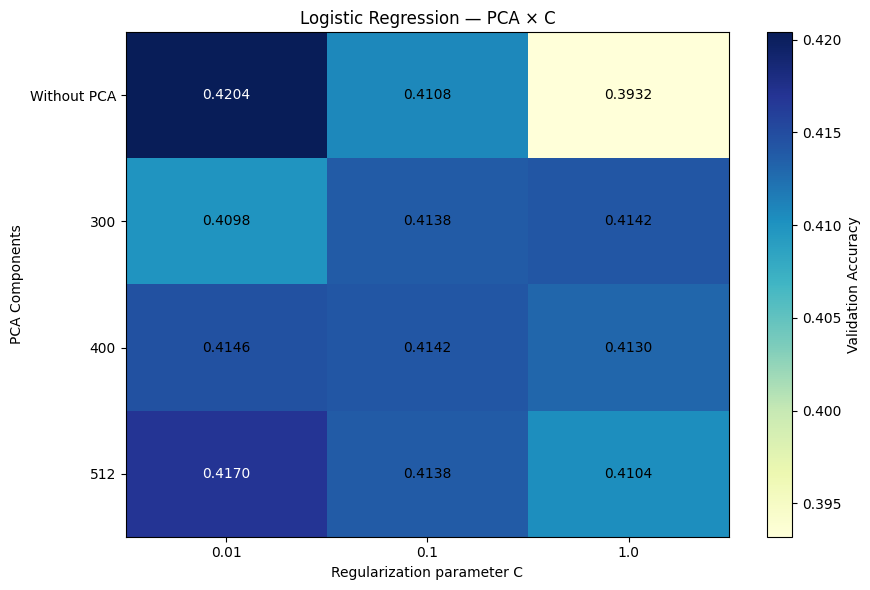

In [11]:
fig, ax = plt.subplots(figsize=(9, 6))

im = ax.imshow(heatmap_data, cmap="YlGnBu", aspect="auto")

fig.colorbar(im, ax=ax, label="Validation Accuracy")

ax.set_xticks(range(len(C_VALUES)))
ax.set_xticklabels(C_VALUES)

ax.set_yticks(range(len(PCA_OPTIONS)))
ax.set_yticklabels([
    "Without PCA" if pca is None else str(pca)
    for pca in PCA_OPTIONS
])

ax.set_xlabel("Regularization parameter C")
ax.set_ylabel("PCA Components")
ax.set_title("Logistic Regression — PCA × C")

for i in range(len(PCA_OPTIONS)):
    for j in range(len(C_VALUES)):
        value = heatmap_data[i, j]

        ax.text(
            j, i, f"{value:.4f}",
            ha="center",
            va="center",
            color="white" if value > 0.415 else "black"
        )

plt.tight_layout()
plt.show()